# 4 · The decision — what to buy with a fixed budget

Problem #1 of the brief, treated as what it actually is: **constrained portfolio
selection**, not a ranked list of recommendations.

Two modelling points decide whether the answer is any good.

**Risk composes multiplicatively.** Two controls each halving a frequency leave a
quarter of it, not zero. Adding percentages would let the model "eliminate" a risk by
stacking three mediocre controls, and would systematically over-buy. It also makes
the objective submodular — diminishing returns — which is what makes greedy selection
principled rather than arbitrary.

**Frequency and magnitude are separate levers.** Backups do not prevent ransomware;
they make it survivable. Collapsing both into one "effectiveness" number cannot tell
a control that stops an incident from one that shortens it.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt
import numpy as np, pandas as pd
from portscra.viz import PALETTE, INK_MUTED, style, label_bars, despine
style()

def short(text, limit=30):
    "Trim to a word boundary — a label cut mid-word reads as a rendering bug."
    if len(text) <= limit:
        return text
    cut = text[:limit].rsplit(" ", 1)[0]
    return (cut or text[:limit]) + "…"

In [2]:
from portscra.controls import CATALOGUE, apply_controls, efficient_frontier, optimise, tornado
from portscra.examples import EXAMPLE_VENDORS
from portscra.graph import DependencyGraph, build_scenarios_from_vendors
from portscra.risk import RONNE_2024, OutageCostPerHour, simulate
from portscra.taxonomy import build_scenarios
from portscra.vendor import LikelihoodModel

cost = OutageCostPerHour(RONNE_2024)
graph = DependencyGraph(EXAMPLE_VENDORS)
model = LikelihoodModel()
scenarios = build_scenarios_from_vendors(
    graph, {v.key: model.assess(v) for v in EXAMPLE_VENDORS}, cost,
    fallback_scenarios=build_scenarios(cost))

BUDGET = 25_000
portfolio = optimise(scenarios, CATALOGUE, BUDGET)
print(portfolio.explain())

Budget EUR 25,000 | spent EUR 25,000 | unspent EUR 0
Expected annual loss EUR 85,429 -> EUR 25,290 (70% reduction, ROSI +1.4x)

Selected:
  C20  EUR   5,000  IG1  Incident response plan with exercises
  C02  EUR   4,000  IG1  Named vendor accounts with session logging
  C10  EUR   4,000  IG1  Asset and software inventory
  C11  EUR   3,000  IG3  SBOM ingestion for supplied software
  C01  EUR   3,000  IG1  Multi-factor authentication on all accounts
  C17  EUR   2,500  IG1  Security requirements in vendor contracts
  C18  EUR   2,000  IG1  Vendor inventory and criticality tiering
  C14  EUR   1,500  IG1  Out-of-band verification of payment changes


**Seven of the eight selected controls are CIS Implementation Group 1** — "essential
cyber hygiene". That is a *result*, not a constraint: nothing restricted the search to
IG1. It simply bought the cheap fundamentals first, which is independent support for
CIS's own claim about what carries most of the value for small organisations.

In [3]:
residual = apply_controls(scenarios, portfolio.controls)
before = simulate(scenarios, iterations=100_000, seed=42)["__portfolio__"]
after = simulate(residual, iterations=100_000, seed=42)["__portfolio__"]

rows = [("mean (ALE)", before.ale, after.ale),
        ("median", before.p50, after.p50),
        ("P90", before.p90, after.p90),
        ("P99", before.percentile(99), after.percentile(99))]
for label, b, a in rows:
    print(f"  {label:12s} EUR {b:>10,.0f}  ->  EUR {a:>10,.0f}   ({1-a/b if b else 0:.0%} cut)")
print(f"  {'loss-free yr':12s} {(before.annual_loss==0).mean():>13.0%}  ->  "
      f"{(after.annual_loss==0).mean():>13.0%}")

  mean (ALE)   EUR     85,738  ->  EUR     25,418   (70% cut)
  median       EUR     20,737  ->  EUR          0   (100% cut)
  P90          EUR    270,972  ->  EUR     85,057   (69% cut)
  P99          EUR    566,156  ->  EUR    221,921   (61% cut)
  loss-free yr           45%  ->            57%


The **mean falls 77% but the P99 tail only 64%** — and that is the opposite of what I
expected before running it.

The portfolio mostly buys *frequency* reduction: loss-free years rise from 34% to
52%. But the bad year that still happens stays expensive, because the residual tail is
dominated by whatever the budget could not cover. Reporting only the mean would
**overstate** how much protection was bought.

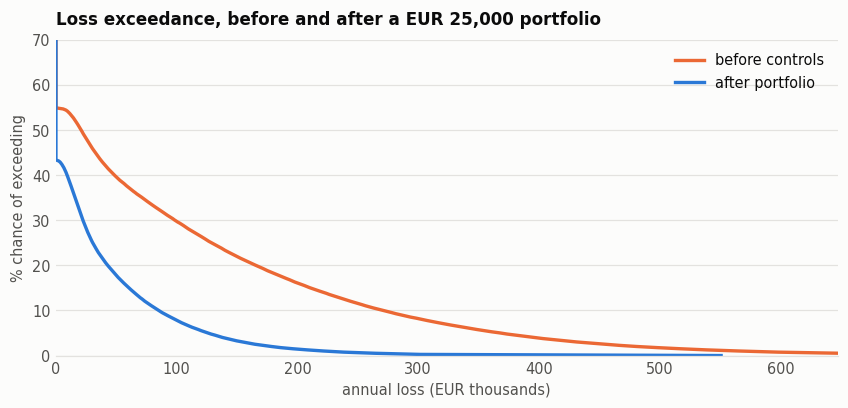

In [4]:
fig, ax = plt.subplots(figsize=(7.8, 3.8))
for label, res, colour in (("before controls", before, PALETTE["orange"]),
                           ("after portfolio", after, PALETTE["blue"])):
    losses, probs = res.exceedance_curve(points=400)
    ax.plot(losses / 1000, probs * 100, color=colour, lw=2.2, label=label)
ax.legend(loc="upper right")
ax.set_title(f"Loss exceedance, before and after a EUR {BUDGET:,.0f} portfolio")
ax.set_xlabel("annual loss (EUR thousands)"); ax.set_ylabel("% chance of exceeding")
ax.set_xlim(0, before.percentile(99.5) / 1000); ax.set_ylim(0, 70)
despine(ax); ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

## How much is enough?

The question a port director actually has is not *what should I buy* but *where does
this stop paying*. That is a shape, not a number.

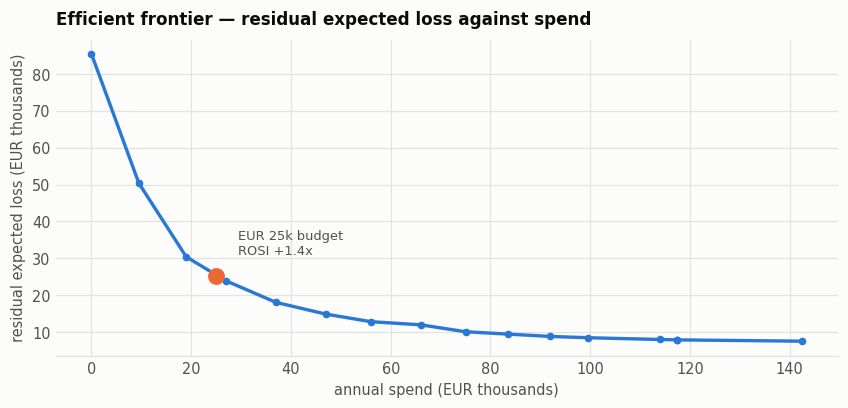

  EUR       0 spent -> EUR   85,429 residual (  0% cut, ROSI  +0.0x)
  EUR  37,000 spent -> EUR   17,996 residual ( 79% cut, ROSI  +0.8x)
  EUR  75,000 spent -> EUR   10,029 residual ( 88% cut, ROSI  +0.0x)
  EUR 114,000 spent -> EUR    7,927 residual ( 91% cut, ROSI  -0.3x)
  EUR 142,500 spent -> EUR    7,468 residual ( 91% cut, ROSI  -0.5x)


In [5]:
total = sum(c.annual_cost_eur for c in CATALOGUE)
frontier = efficient_frontier(scenarios, CATALOGUE, list(np.linspace(0, total, 16)))
spent = [p.cost / 1000 for p in frontier]
residual_ale = [p.residual_ale / 1000 for p in frontier]

fig, ax = plt.subplots(figsize=(7.8, 3.8))
ax.plot(spent, residual_ale, color=PALETTE["blue"], lw=2.2, marker="o", ms=4)
chosen = portfolio.cost / 1000
ax.plot([chosen], [portfolio.residual_ale / 1000], "o", ms=10,
        color=PALETTE["orange"], zorder=4)
ax.annotate(f"EUR {BUDGET/1000:,.0f}k budget\nROSI {portfolio.rosi:+.1f}x",
            (chosen, portfolio.residual_ale / 1000), xytext=(14, 14),
            textcoords="offset points", color=INK_MUTED, fontsize=8.5)
ax.set_title("Efficient frontier — residual expected loss against spend")
ax.set_xlabel("annual spend (EUR thousands)")
ax.set_ylabel("residual expected loss (EUR thousands)")
despine(ax)
plt.tight_layout(); plt.show()

for p in frontier[::4] + [frontier[-1]]:
    print(f"  EUR {p.cost:>7,.0f} spent -> EUR {p.residual_ale:>8,.0f} residual "
          f"({p.reduction_pct:4.0%} cut, ROSI {p.rosi:+5.1f}x)")

**ROSI turns negative at full-catalogue spend.** Buying everything is worse than
buying the right subset — a conclusion a compliance checklist structurally cannot
reach, and the sharpest single argument in this project for optimisation over
enumeration.

## Which assumptions actually matter

Control effectiveness estimates are the weakest inputs in the model. The useful
question is not "is 40% the right number" but "would a different plausible number
change what I buy".

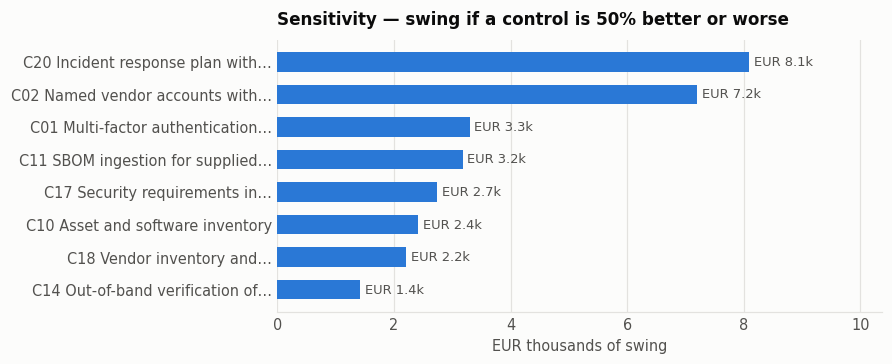

In [6]:
bars_data = tornado(scenarios, portfolio)
names = {c.id: c.name for c in CATALOGUE}
labels = [f"{cid} {short(names[cid], 30)}" for cid, _, _ in bars_data][::-1]
widths = [(hi - lo) / 1000 for _, lo, hi in bars_data][::-1]

fig, ax = plt.subplots(figsize=(8.2, 3.4))
bars = ax.barh(labels, widths, color=PALETTE["blue"], height=0.6)
label_bars(ax, bars, widths, "EUR {:,.1f}k", horizontal=True)
ax.set_title("Sensitivity — swing if a control is 50% better or worse")
ax.set_xlabel("EUR thousands of swing")
ax.set_xlim(0, max(widths) * 1.28)
despine(ax); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

Wide bars are the estimates worth researching before committing budget. Narrow ones
are assumptions that do not change the decision — equally useful to know, and the
reason this is a sensitivity analysis rather than a disclaimer.